# Laboratorio 10 — Comparativa con nuevas señales EMG

Este cuaderno **no reemplaza** el notebook del profesor: reutiliza sus funciones (lectura OpenSignals, conversión a mV, filtrado 20–450 Hz + notch 60 Hz, envolvente RMS, detección con umbral intra-registro, ventaneo de 250 ms, 15 características, Fisher, LDA/SVM con `GroupKFold`) y las aplica a los registros medidos el 4/09/2026, para **comparar** con los resultados de `PRUEBABRAZO1`.

### Cambios mínimos respecto al notebook original (y por qué)
| # | Cambio | Motivo |
|---|---|---|
| 1 | `leer_opensignals` detecta el canal (`A6` en estos archivos) en lugar de fijar `"A1"` | Con `"A1"` el original falla: la columna no existe en estos archivos |
| 2 | Cada registro usa **el baseline de su misma sesión y región** (brazo o dedo/mano) para el ruido, la SNR y ε | El original usa un solo baseline (`BASELINEBRAZO`) |
| 3 | Si hay menos de 5 contracciones, `GroupKFold` agrupa por **6 bloques de tiempo** en vez de por ciclo | Estos registros son rampas de ~30 s con 1–3 segmentos largos: no hay ciclos reposo/contracción |
| 4 | Saturación contada con `adc >= 2**N_BITS - 2` | Es el criterio corregido del propio solucionario |
| 5 | Los archivos `*base*` solo se usan como baseline y para medir ruido | Un registro de reposo no tiene contracciones que clasificar |
| 6 | La CNN del Bloque 7 se aplica a cada registro con la **misma arquitectura y el mismo `entrenar_cnn`**; solo se reutilizan las máscaras/grupos de la sección 4 y se fija la semilla por registro | Comparabilidad y reproducibilidad |

Todo lo demás (umbral = media + 5·σ del 20 % de menor envolvente, ventana 250 ms con 50 % de solape, etiquetado 80 %/5 %) se mantiene igual.

In [1]:
import os, sys, re, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import kurtosis, skew, spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupKFold, cross_val_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOR_REPOSO, COLOR_CONTRAC, COLOR_UPCH = "#4C72B0", "#C44E52", "#7F000E"
try:
    from IPython.display import display
except ImportError:
    display = print
EN_COLAB = "google.colab" in sys.modules
print("Entorno listo.")

Entorno listo.


## 1. Localización de los archivos
Busca por **nombre normalizado** (sin espacios, guiones bajos ni paréntesis), así encuentra `MOV LEVE 03 (dedo mano).txt` en Drive y `MOV_LEVE_03__dedo_mano_.txt` si se subió a mano. En Colab monta Drive si hace falta.

In [2]:
RUTA_DRIVE = "/content/drive/MyDrive/Intro Señales Biomedica (Grupo 9)/Avance LAB8/Archivos recolectados para prueba/"

if EN_COLAB and not os.path.isdir(RUTA_DRIVE):
    from google.colab import drive
    drive.mount("/content/drive")

CARPETAS = [RUTA_DRIVE, ".", "/content", "/mnt/user-data/uploads"]
norm = lambda s: re.sub(r"[^a-z0-9]", "", os.path.splitext(os.path.basename(s))[0].lower())

indice = {}
for carpeta in CARPETAS:
    if os.path.isdir(carpeta):
        for f in glob.glob(os.path.join(carpeta, "*.txt")):
            indice.setdefault(norm(f), f)
print(f"Archivos .txt visibles: {len(indice)}")

# Metadatos del protocolo (fuente: nombres de archivo y cabeceras OpenSignals)
REGISTROS = [
    dict(clave="Prueba 01 base (brazo)",      region="Brazo",      tipo="baseline",  base=None),
    dict(clave="MOV LEVE 02 (brazo)",         region="Brazo",      tipo="actividad", base="Prueba 01 base (brazo)"),
    dict(clave="OPOSICION 02 (brazo)",        region="Brazo",      tipo="actividad", base="Prueba 01 base (brazo)"),
    dict(clave="Prueba 02 base (dedo mano)",  region="Dedo/mano",  tipo="baseline",  base=None),
    dict(clave="MOV LEVE 03 (dedo mano)",     region="Dedo/mano",  tipo="actividad", base="Prueba 02 base (dedo mano)"),
    dict(clave="OPOSICION 01 (dedo mano)",    region="Dedo/mano",  tipo="actividad", base="Prueba 02 base (dedo mano)"),
    # Referencia del solucionario: se calcula en vivo solo si los archivos originales están disponibles
    dict(clave="BASELINEBRAZO",               region="Brazo",      tipo="baseline",  base=None, opcional=True),
    dict(clave="PRUEBABRAZO1",                region="Brazo",      tipo="actividad", base="BASELINEBRAZO", opcional=True),
]
disponibles = []
for r in REGISTROS:
    r["ruta"] = indice.get(norm(r["clave"]))
    if r["ruta"] is None:
        print(("(opcional, no encontrado) " if r.get("opcional") else "⚠️ NO ENCONTRADO: ") + r["clave"])
    else:
        disponibles.append(r)
print(f"Registros a procesar: {len(disponibles)}")

Mounted at /content/drive
Archivos .txt visibles: 8
Registros a procesar: 8


## 2. Funciones del notebook del profesor
Idénticas al original, salvo `leer_opensignals` (cambio 1) y que `fs`/`eps` se pasan como argumento en vez de leerse de variables globales.

In [3]:
def leer_opensignals(ruta, etiqueta_canal=None):
    # CAMBIO 1: si no se indica canal, se toma el primer canal analógico (A1, A6, ...) de la cabecera
    with open(ruta, "r", encoding="utf-8") as f:
        cabecera = [next(f) for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    datos = np.loadtxt(ruta, comments="#")
    if etiqueta_canal is None:
        etiqueta_canal = [c for c in meta["column"] if c.startswith("A")][0]
    idx = meta["column"].index(etiqueta_canal)
    meta["bits"] = meta["resolution"][idx]
    meta["canal"] = etiqueta_canal
    return datos[:, idx].astype(float), meta

VCC, G_EMG = 3.3, 1009
def adc_a_mV(adc, n_bits=10, vcc=VCC, ganancia=G_EMG):
    return ((adc / 2**n_bits) - 0.5) * vcc / ganancia * 1000

def filtrar_emg(x, fs, f_baja=20, f_alta=450, orden=4, f_notch=60, q_notch=30):
    if not (0 < f_baja < f_alta < fs/2):
        raise ValueError(f"Se requiere 0 < f_baja < f_alta < Fs/2 (Fs = {fs} Hz).")
    sos = signal.butter(orden, [f_baja, f_alta], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if f_notch:
        b, a = signal.iirnotch(f_notch, q_notch, fs=fs)
        y = signal.filtfilt(b, a, y)
    return y

def envolvente_rms(x, fs, ventana_ms=200):
    w = max(1, int(fs * ventana_ms / 1000))
    return np.sqrt(np.convolve(x**2, np.ones(w)/w, mode="same"))

def limpiar_mascara(activo, fs, hueco_min_s=0.25, dur_min_s=0.30):
    d = np.diff(np.r_[0, activo.astype(int), 0])
    inicios, fines = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    segs = []
    for s, e in zip(inicios, fines):
        if segs and s - segs[-1][1] < hueco_min_s * fs:
            segs[-1] = (segs[-1][0], e)
        else:
            segs.append((s, e))
    segs = [(s, e) for s, e in segs if (e - s) >= dur_min_s * fs]
    mascara = np.zeros(len(activo), dtype=bool)
    for s, e in segs:
        mascara[s:e] = True
    return mascara, segs

def crear_ventanas(x, fs, ventana_ms=250, solapamiento=0.5):
    n = int(round(fs * ventana_ms / 1000))
    paso = max(1, int(round(n * (1 - solapamiento))))
    inicios = np.arange(0, len(x) - n + 1, paso)
    return np.stack([x[i:i+n] for i in inicios]), inicios

def caracteristicas_temporales(x, eps):
    dx = np.diff(x)
    zc  = np.sum((x[:-1] * x[1:] < 0) & (np.abs(dx) >= eps))
    ssc = np.sum(((dx[:-1] * dx[1:]) < 0) & ((np.abs(dx[:-1]) >= eps) | (np.abs(dx[1:]) >= eps)))
    return {"MAV": np.mean(np.abs(x)), "RMS": np.sqrt(np.mean(x**2)), "iEMG": np.sum(np.abs(x)),
            "VAR": np.var(x, ddof=1), "WL": np.sum(np.abs(dx)), "ZC": zc, "SSC": ssc,
            "WAMP": np.sum(np.abs(dx) > eps), "Asimetria": skew(x), "Curtosis": kurtosis(x, fisher=True, bias=False)}

def caracteristicas_frecuenciales(x, fs, nperseg=128):
    f, p = signal.welch(x, fs=fs, nperseg=min(nperseg, len(x)))
    banda = (f >= 20) & (f <= 450)
    f, p = f[banda], p[banda]
    p_tot = p.sum(); acum = np.cumsum(p)
    pot = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() / p_tot
    return {"MNF": np.sum(f * p) / p_tot, "MDF": f[np.searchsorted(acum, acum[-1] / 2)],
            "P_20_80": pot(20, 80), "P_80_150": pot(80, 150), "P_150_450": pot(150, 451)}

def extraer_caracteristicas(x, fs, eps):
    c = caracteristicas_temporales(x, eps)
    c.update(caracteristicas_frecuenciales(x, fs))
    return c

def razon_fisher(d, cols):
    a, b = d[d.etiqueta == "reposo"], d[d.etiqueta == "contraccion"]
    return (a[cols].mean() - b[cols].mean())**2 / (a[cols].var() + b[cols].var())

## 3. Lectura, conversión y filtrado de todos los registros

In [4]:
datos = {}
for r in disponibles:
    adc, meta = leer_opensignals(r["ruta"])
    fs, bits = int(meta["sampling rate"]), int(meta["bits"])
    mv = adc_a_mV(adc, bits)
    datos[r["clave"]] = dict(adc=adc, meta=meta, fs=fs, bits=bits, mv=mv, filt=filtrar_emg(mv, fs), reg=r)

assert len({d["fs"] for d in datos.values()}) == 1, "Hay registros con Fs distintas."
FS = next(iter(datos.values()))["fs"]

filas = []
for k, d in datos.items():
    m = d["meta"]
    filas.append({"Archivo": k, "Región": d["reg"]["region"], "Tipo": d["reg"]["tipo"], "Canal": m["canal"],
                  "Sensor": m["sensor"][0], "Fecha-hora": f"{m['date']} {m['time'].split('.')[0]}",
                  "Fs (Hz)": d["fs"], "Bits": d["bits"], "Duración (s)": round(len(d["adc"])/d["fs"], 1),
                  "ADC min/max": f"{d['adc'].min():.0f}/{d['adc'].max():.0f}"})
display(pd.DataFrame(filas))

,Archivo,Región,Tipo,Canal,Sensor,Fecha-hora,Fs (Hz),Bits,Duración (s),ADC min/max
0,Prueba 01 base (brazo),Brazo,baseline,A6,EMGBITREV,2026-9-4 15:58:36,1000,10,30.6,499/521
1,MOV LEVE 02 (brazo),Brazo,actividad,A6,EMGBITREV,2026-9-4 16:2:38,1000,10,38.4,347/621
2,OPOSICION 02 (brazo),Brazo,actividad,A6,EMGBITREV,2026-9-4 16:7:41,1000,10,33.9,0/1023
3,Prueba 02 base (dedo mano),Dedo/mano,baseline,A6,EMGBITREV,2026-9-4 16:38:9,1000,10,31.1,398/668
4,MOV LEVE 03 (dedo mano),Dedo/mano,actividad,A6,EMGBITREV,2026-9-4 16:42:3,1000,10,28.5,30/1022
5,OPOSICION 01 (dedo mano),Dedo/mano,actividad,A6,EMGBITREV,2026-9-4 16:44:21,1000,10,31.5,0/1023
6,BASELINEBRAZO,Brazo,baseline,A1,EMGBITREV,2026-4-17 12:23:25,1000,10,69.2,498/524
7,PRUEBABRAZO1,Brazo,actividad,A1,EMGBITREV,2026-4-17 12:18:23,1000,10,63.1,0/1023


## 4. Análisis de cada registro con el pipeline del profesor
`analizar()` encadena los pasos del solucionario: calidad (saturación, ruido, SNR), detección con umbral intra-registro, ventaneo/etiquetado, características, Fisher y clasificación con `GroupKFold`.

In [5]:
rms = lambda v: np.sqrt(np.mean(v**2))

def analizar(clave, K=5, ventana_ms=250, solap=0.5):
    d = datos[clave]; reg = d["reg"]; fs = d["fs"]; xf = d["filt"]
    base_f = datos[reg["base"]]["filt"] if reg["base"] in datos else (xf if reg["tipo"] == "baseline" else None)
    out = {"Archivo": clave, "Región": reg["region"], "Tipo": reg["tipo"]}

    # --- Calidad (bloques 2-3) ---
    out["Sat. (%) (≥1022)"] = round(100 * np.mean((d["adc"] <= 0) | (d["adc"] >= 2**d["bits"] - 2)), 3)
    out["RMS filtrado (µV)"] = round(rms(xf) * 1000, 1)
    if base_f is not None and reg["tipo"] == "actividad":
        out["RMS baseline (µV)"] = round(rms(base_f) * 1000, 1)
        out["SNR (dB)"] = round(20 * np.log10(rms(xf) / rms(base_f)), 1)
    eps = 3 * np.std(base_f) if base_f is not None else np.nan
    out["ε (µV)"] = round(eps * 1000, 1)

    # --- Detección (bloque 4): umbral intra-registro ---
    env = envolvente_rms(xf, fs)
    ref = env[env <= np.percentile(env, 20)]
    umbral = ref.mean() + K * ref.std()
    mascara, segs = limpiar_mascara(env > umbral, fs)
    dur = np.array([(e - s) / fs for s, e in segs])
    out["Umbral (µV)"] = round(umbral * 1000, 1)
    out["Segmentos detectados"] = len(segs)
    out["Duración segmentos (s)"] = ", ".join(f"{v:.1f}" for v in dur[:6]) + ("…" if len(dur) > 6 else "")
    out["% tiempo activo"] = round(100 * mascara.mean(), 1)
    d["env"], d["umbral"], d["segs"], d["mascara"] = env, umbral, segs, mascara

    # Espectro de los tramos activos (como la verificación del bloque 3)
    if mascara.sum() >= 1024:
        f_c, P_c = signal.welch(xf[mascara], fs=fs, nperseg=1024)
        acum = np.cumsum(P_c)
        out["Pico espectral activo (Hz)"] = round(f_c[np.argmax(P_c)])
        out["MDF activa (Hz)"] = round(f_c[np.searchsorted(acum, acum[-1] / 2)])
        out["% potencia 20–150 Hz"] = round(100 * P_c[(f_c >= 20) & (f_c < 150)].sum() / P_c.sum(), 1)

    if reg["tipo"] != "actividad" or len(segs) == 0:
        return out

    # --- Ventaneo y etiquetado (bloque 4) ---
    ventanas, inicios = crear_ventanas(xf, fs, ventana_ms, solap)
    n_win = ventanas.shape[1]
    frac = np.array([mascara[i:i+n_win].mean() for i in inicios])
    etiqueta = np.where(frac >= 0.8, "contraccion", np.where(frac <= 0.05, "reposo", "transicion"))
    out["Ventanas reposo/contr./trans."] = f"{(etiqueta=='reposo').sum()}/{(etiqueta=='contraccion').sum()}/{(etiqueta=='transicion').sum()}"

    # --- Grupos para GroupKFold (CAMBIO 3) ---
    if len(segs) >= 5:
        ini_c = np.array([s for s, _ in segs])
        ciclo = np.searchsorted(ini_c, inicios + n_win // 2, side="right")
        ciclo = np.where(etiqueta == "reposo", np.searchsorted(ini_c, inicios, side="left"), ciclo - 1)
        grupos = np.clip(ciclo, 0, len(segs) - 1); out["Grupos"] = "ciclos"
    else:
        grupos = np.minimum(inicios // (len(xf) // 6), 5); out["Grupos"] = "6 bloques de tiempo"

    # --- Características (bloque 5) ---
    df = pd.DataFrame([extraer_caracteristicas(w, fs, eps) for w in ventanas])
    CAR = list(df.columns)
    df["etiqueta"], df["grupo"] = etiqueta, grupos
    d["df"], d["CAR"] = df, CAR
    df_ml = df[df.etiqueta != "transicion"].copy()
    n_r, n_c = (df_ml.etiqueta == "reposo").sum(), (df_ml.etiqueta == "contraccion").sum()
    if n_r < 10 or n_c < 10:
        out["Clasificación"] = f"no evaluable (reposo={n_r}, contracción={n_c})"
        return out
    out["RMS reposo (µV)"] = round(df_ml[df_ml.etiqueta == "reposo"].RMS.mean() * 1000, 1)
    out["RMS contracción (µV)"] = round(df_ml[df_ml.etiqueta == "contraccion"].RMS.mean() * 1000, 1)
    fisher = razon_fisher(df_ml, CAR).sort_values(ascending=False)
    out["Top-3 Fisher"] = ", ".join(f"{k} ({v:.1f})" for k, v in fisher.head(3).items())

    # --- Clasificación (bloque 6) ---
    y = (df_ml.etiqueta == "contraccion").astype(int).values
    g = df_ml.grupo.values
    n_g = len(np.unique(g))
    if n_g < 3:
        out["Clasificación"] = "no evaluable (menos de 3 grupos)"
        return out
    cv = GroupKFold(n_splits=min(5, n_g))
    out["Pliegues con ambas clases en prueba"] = f"{sum(len(np.unique(y[te])) == 2 for _, te in cv.split(df_ml, y, g))}/{cv.get_n_splits()}"
    modelos = {"LDA (15 car.)": (make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), CAR),
               "SVM-RBF (15 car.)": (make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")), CAR),
               "Umbral en RMS": (DecisionTreeClassifier(max_depth=1, random_state=0), ["RMS"])}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for nombre, (mod, cols) in modelos.items():
            s = cross_val_score(mod, df_ml[cols].values, y, cv=cv, groups=g, scoring="balanced_accuracy", error_score=np.nan)
            out[nombre] = round(float(np.nanmean(s)), 3) if np.isfinite(s).any() else np.nan
    return out

resultados = [analizar(k) for k in datos]
tabla = pd.DataFrame(resultados).set_index("Archivo")
display(tabla.T)

Archivo,Prueba 01 base (brazo),MOV LEVE 02 (brazo),OPOSICION 02 (brazo),Prueba 02 base (dedo mano),MOV LEVE 03 (dedo mano),OPOSICION 01 (dedo mano),BASELINEBRAZO,PRUEBABRAZO1
Región,Brazo,Brazo,Brazo,Dedo/mano,Dedo/mano,Dedo/mano,Brazo,Brazo
Tipo,baseline,actividad,actividad,baseline,actividad,actividad,baseline,actividad
Sat. (%) (≥1022),0.0,0.0,0.165,0.0,0.021,0.279,0.0,0.435
RMS filtrado (µV),4.5,30.1,221.0,57.8,181.6,311.7,5.9,230.2
ε (µV),13.4,13.4,13.4,173.5,173.5,173.5,17.6,17.6
Umbral (µV),4.7,14.6,52.3,64.1,48.9,127.4,6.1,43.2
Segmentos detectados,5,3,2,1,1,3,22,21
Duración segmentos (s),"0.6, 0.4, 0.3, 1.3, 1.2","12.6, 7.6, 3.2","15.5, 5.5",4.7,19.9,"18.9, 0.4, 2.4","0.6, 8.7, 0.4, 5.6, 1.4, 1.4…","1.9, 1.7, 1.3, 1.2, 1.7, 1.4…"
% tiempo activo,12.5,61.0,62.0,15.2,69.7,68.8,46.7,41.8
Pico espectral activo (Hz),180,54,47,120,120,120,120,76


## 5. Detección sobre cada registro
Franjas rosadas = segmentos que el método del profesor marca como contracción; línea discontinua = umbral intra-registro.

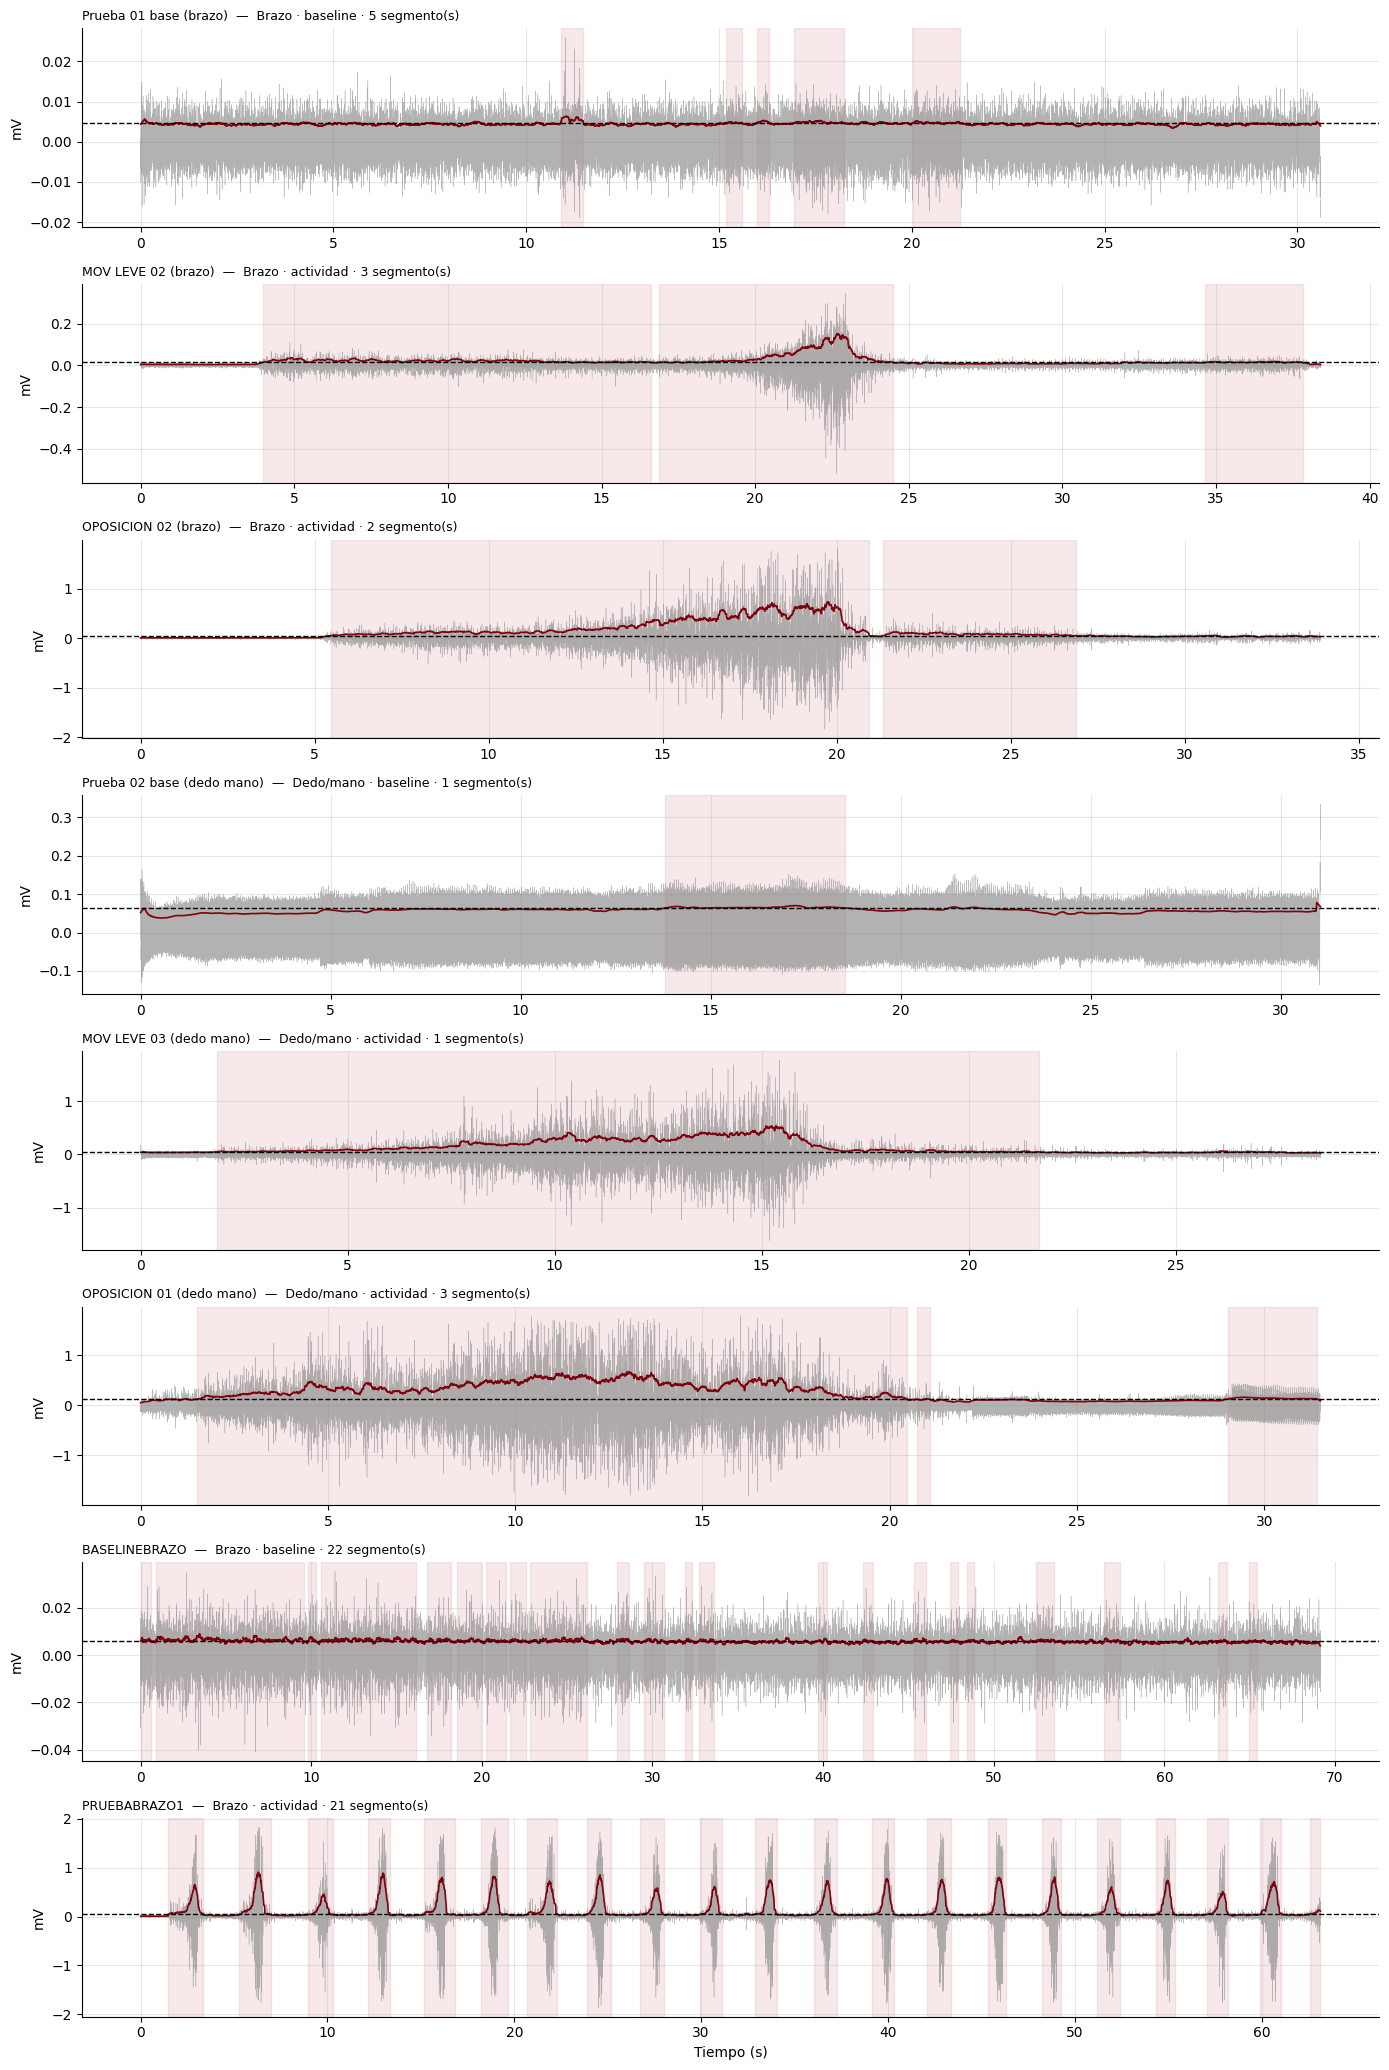

In [6]:
claves = list(datos)
fig, ax = plt.subplots(len(claves), 1, figsize=(14, 2.6 * len(claves)))
for a, k in zip(np.atleast_1d(ax), claves):
    d = datos[k]; t = np.arange(len(d["filt"])) / d["fs"]
    a.plot(t, d["filt"], lw=0.3, color="gray", alpha=0.6)
    a.plot(t, d["env"], lw=1.2, color=COLOR_UPCH)
    a.axhline(d["umbral"], color="k", ls="--", lw=1)
    for s, e in d["segs"]:
        a.axvspan(s / d["fs"], e / d["fs"], color=COLOR_CONTRAC, alpha=0.12)
    a.set_title(f"{k}  —  {d['reg']['region']} · {d['reg']['tipo']} · {len(d['segs'])} segmento(s)", loc="left", fontsize=9)
    a.set_ylabel("mV")
np.atleast_1d(ax)[-1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

## 6. Complemento: evolución del esfuerzo en las rampas
**Esto no está en el notebook del profesor.** Como los registros `MOV LEVE` y `OPOSICION` son una subida y bajada de esfuerzo, se calculan RMS, MNF y MDF por bloques de 2 s para ver cómo cambia el espectro con la amplitud (misma lógica de características del bloque 5, con `nperseg = 512` para afinar la MDF a ~2 Hz).

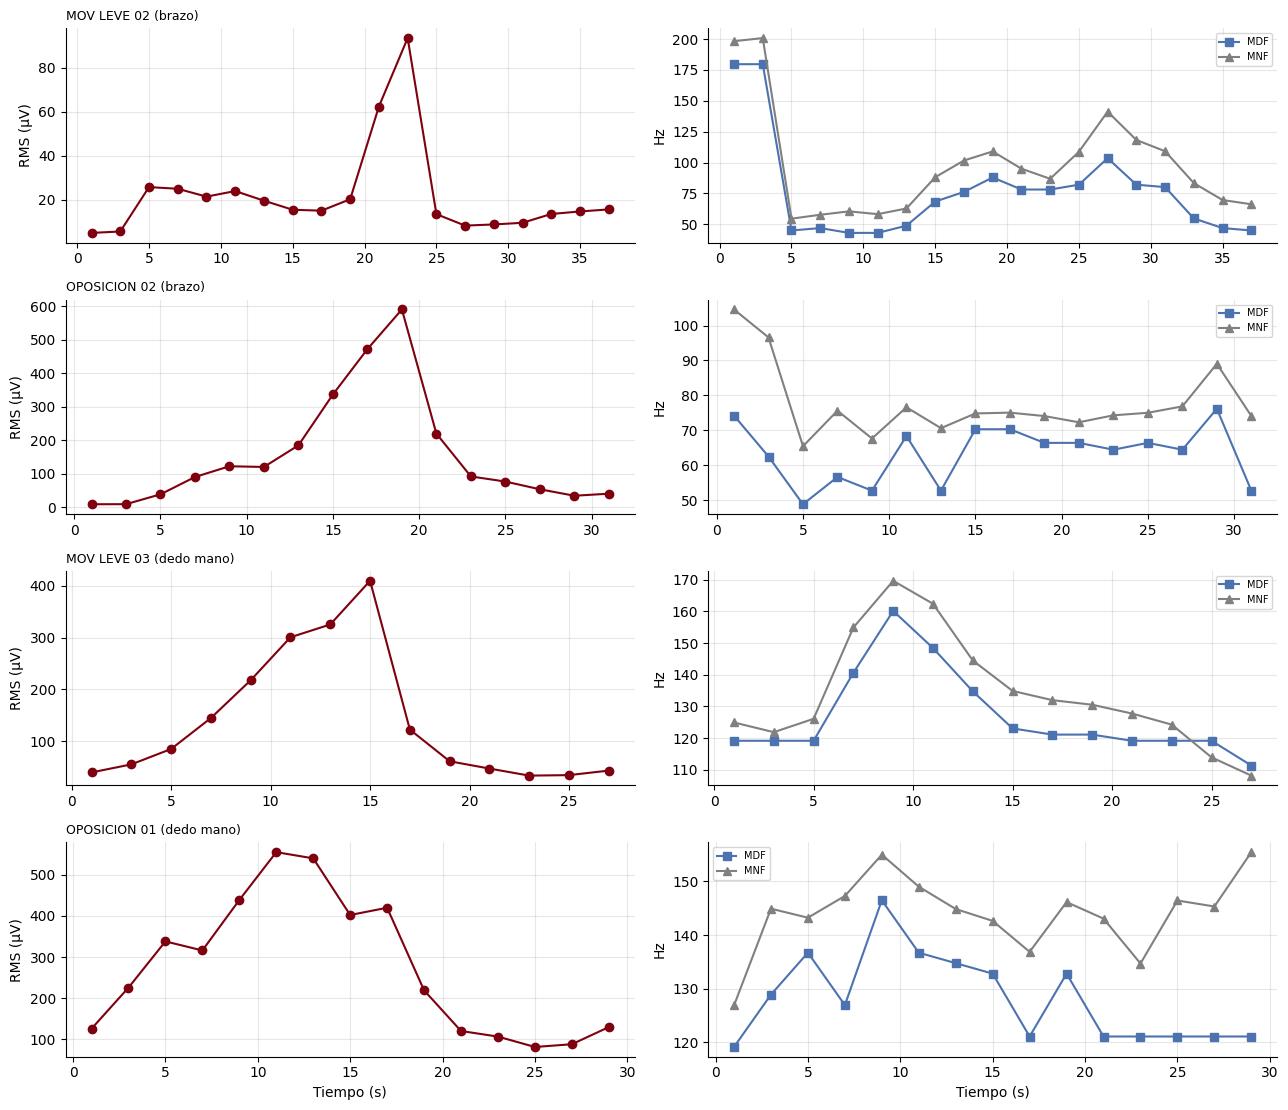

,RMS pico (µV),Instante del pico (s),Razón pico/inicio,MDF mediana (Hz),ρ Spearman RMS–MDF,p
Archivo,,,,,,
MOV LEVE 02 (brazo),94,23.0,17.7,76,-0.63,0.004
OPOSICION 02 (brazo),591,19.0,66.6,65,0.09,0.735
MOV LEVE 03 (dedo mano),410,15.0,8.7,120,0.82,0.000
OPOSICION 01 (dedo mano),555,11.0,3.2,127,0.76,0.001


In [7]:
def rampa(clave, bloque_s=2.0):
    d = datos[clave]; fs = d["fs"]; xf = d["filt"]; n = int(bloque_s * fs)
    filas = []
    for i in range(0, len(xf) - n + 1, n):
        seg = xf[i:i+n]
        c = caracteristicas_frecuenciales(seg, fs, nperseg=512)
        filas.append({"t_s": (i + n / 2) / fs, "RMS_uV": rms(seg) * 1000, "MNF": c["MNF"], "MDF": c["MDF"]})
    return pd.DataFrame(filas)

activos = [k for k in datos if datos[k]["reg"]["tipo"] == "actividad" and k != "PRUEBABRAZO1"]
fig, ax = plt.subplots(len(activos), 2, figsize=(13, 2.8 * len(activos)))
ax = np.atleast_2d(ax)
resumen_rampa = []
for fila, k in zip(ax, activos):
    r = rampa(k)
    fila[0].plot(r.t_s, r.RMS_uV, "o-", color=COLOR_UPCH); fila[0].set_ylabel("RMS (µV)")
    fila[0].set_title(f"{k}", loc="left", fontsize=9)
    fila[1].plot(r.t_s, r.MDF, "s-", color=COLOR_REPOSO, label="MDF"); fila[1].plot(r.t_s, r.MNF, "^-", color="gray", label="MNF")
    fila[1].set_ylabel("Hz"); fila[1].legend(fontsize=7)
    rho, p = spearmanr(r.RMS_uV, r.MDF)
    resumen_rampa.append({"Archivo": k, "RMS pico (µV)": round(r.RMS_uV.max()), "Instante del pico (s)": round(r.t_s[r.RMS_uV.idxmax()], 1),
                          "Razón pico/inicio": round(r.RMS_uV.max() / r.RMS_uV.iloc[:2].mean(), 1),
                          "MDF mediana (Hz)": round(r.MDF.median()), "ρ Spearman RMS–MDF": round(rho, 2), "p": round(p, 3)})
ax[-1, 0].set_xlabel("Tiempo (s)"); ax[-1, 1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(resumen_rampa).set_index("Archivo"))

## 7. CNN con espectrogramas (Bloque 7 del profesor)
`CNNEspectrograma`, `entrenar_cnn` y `espectrograma` son **idénticas al original** (Conv 8 → Conv 16 → promedio global → lineal, 40 épocas, Adam 1e-2). Lo único que cambia es la preparación de datos por registro: ventanas de 500 ms con 50 % de solape, etiqueta 1/0/−1 con la misma máscara de la sección 4 (≥ 80 % / ≤ 5 %), y los mismos grupos para `GroupKFold`. Requiere PyTorch (viene instalado en Colab).

In [8]:
from sklearn.metrics import balanced_accuracy_score
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch")

def espectrograma(x, fs, nperseg=64, noverlap=48):
    f, t, S = signal.stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap, boundary=None)
    banda = (f >= 20) & (f <= 450)
    return f[banda], t, np.log10(np.abs(S[banda])**2 + 1e-10)

if TORCH_OK:
    torch.manual_seed(0)

    class CNNEspectrograma(nn.Module):
        def __init__(self, n_clases=2):
            super().__init__()
            self.extractor = nn.Sequential(
                nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.AdaptiveAvgPool2d(1),
            )
            self.clasificador = nn.Linear(16, n_clases)
        def forward(self, x):
            return self.clasificador(self.extractor(x).flatten(1))

    def entrenar_cnn(X_tr, y_tr, X_te, epocas=40, lr=1e-2):
        mu, sd = X_tr.mean(), X_tr.std()
        Xtr = torch.tensor((X_tr - mu) / sd).unsqueeze(1)
        Xte = torch.tensor((X_te - mu) / sd).unsqueeze(1)
        ytr = torch.tensor(y_tr, dtype=torch.long)
        modelo = CNNEspectrograma()
        opt = torch.optim.Adam(modelo.parameters(), lr=lr)
        perdida_fn = nn.CrossEntropyLoss()
        historial = []
        for _ in range(epocas):
            modelo.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(Xtr), 32):
                idx = perm[i:i+32]
                if len(idx) < 2:      # BatchNorm necesita al menos 2 muestras por lote
                    continue
                opt.zero_grad()
                loss = perdida_fn(modelo(Xtr[idx]), ytr[idx])
                loss.backward(); opt.step()
            historial.append(loss.item())
        modelo.eval()
        with torch.no_grad():
            pred = modelo(Xte).argmax(1).numpy()
        return pred, historial, modelo

    print("Parámetros entrenables:", sum(p.numel() for p in CNNEspectrograma().parameters() if p.requires_grad))

Parámetros entrenables: 1330


In [9]:
def datos_cnn(clave, ventana_ms=500, solap=0.5):
    # Misma lógica que el bloque 7 del original, usando la máscara y los segmentos ya detectados
    d = datos[clave]; fs = d["fs"]; xf = d["filt"]; segs = d["segs"]; mascara = d["mascara"]
    win, ini = crear_ventanas(xf, fs, ventana_ms, solap)
    n = win.shape[1]
    frac = np.array([mascara[i:i+n].mean() for i in ini])
    lab = np.where(frac >= 0.8, 1, np.where(frac <= 0.05, 0, -1))
    if len(segs) >= 5:      # ciclos, como el original
        ini_c = np.array([s for s, _ in segs])
        grupos = np.clip(np.where(lab == 0, np.searchsorted(ini_c, ini, side="left"),
                                  np.searchsorted(ini_c, ini + n // 2, side="right") - 1), 0, len(segs) - 1)
    else:                   # cambio 3: 6 bloques de tiempo
        grupos = np.minimum(ini // (len(xf) // 6), 5)
    ok = lab >= 0
    imgs = np.stack([espectrograma(w, fs)[2] for w in win[ok]]).astype(np.float32)
    return imgs, lab[ok], grupos[ok]

resultados_cnn = {}
for k in datos:
    d = datos[k]
    if d["reg"]["tipo"] != "actividad" or len(d["segs"]) == 0:
        continue
    imgs, lab, g = datos_cnn(k)
    n_g = len(np.unique(g))
    info = {"imagenes": len(lab), "reposo": int((lab == 0).sum()), "contraccion": int((lab == 1).sum()), "forma": imgs.shape[1:]}
    if min(info["reposo"], info["contraccion"]) < 10 or n_g < 3:
        info["exactitud"] = np.nan; info["pliegues"] = "no evaluable"
    elif TORCH_OK:
        torch.manual_seed(0)          # semilla por registro: resultados repetibles
        cv = GroupKFold(n_splits=min(5, n_g)); accs, informativos = [], 0
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            for tr, te in cv.split(imgs, lab, g):
                informativos += int(len(np.unique(lab[te])) == 2)
                if len(np.unique(lab[tr])) < 2:
                    accs.append(np.nan); continue
                pred, _, _ = entrenar_cnn(imgs[tr], lab[tr], imgs[te])
                accs.append(balanced_accuracy_score(lab[te], pred))
        info["exactitud"] = round(float(np.nanmean(accs)), 3) if np.isfinite(accs).any() else np.nan
        info["pliegues"] = f"{informativos}/{cv.get_n_splits()}"
    else:
        info["exactitud"] = "N/D (sin PyTorch)"; info["pliegues"] = "—"
    resultados_cnn[k] = info
    print(f"{k:28s} imágenes {info['imagenes']:3d} (reposo {info['reposo']}, contracción {info['contraccion']}) forma {info['forma']} | CNN: {info['exactitud']} | pliegues con ambas clases: {info['pliegues']}")

tabla["CNN (STFT 500 ms)"] = [resultados_cnn.get(k, {}).get("exactitud", np.nan) for k in tabla.index]
tabla["CNN: pliegues con ambas clases"] = [resultados_cnn.get(k, {}).get("pliegues", np.nan) for k in tabla.index]

MOV LEVE 02 (brazo)          imágenes 142 (reposo 53, contracción 89) forma (27, 29) | CNN: 0.742 | pliegues con ambas clases: 3/5
OPOSICION 02 (brazo)         imágenes 128 (reposo 46, contracción 82) forma (27, 29) | CNN: 0.862 | pliegues con ambas clases: 2/5
MOV LEVE 03 (dedo mano)      imágenes 110 (reposo 32, contracción 78) forma (27, 29) | CNN: 0.921 | pliegues con ambas clases: 2/5
OPOSICION 01 (dedo mano)     imágenes 119 (reposo 35, contracción 84) forma (27, 29) | CNN: 0.959 | pliegues con ambas clases: 2/5
PRUEBABRAZO1                 imágenes 185 (reposo 106, contracción 79) forma (27, 29) | CNN: 0.981 | pliegues con ambas clases: 5/5


## 8. Comparativa con el solucionario (`PRUEBABRAZO1`)
Si `BASELINEBRAZO.txt` y `PRUEBABRAZO1.txt` están en la misma carpeta, la fila de referencia sale de este mismo código. Si no, se usan los valores impresos en el solucionario (celda siguiente).

In [10]:
# Valores impresos en el solucionario del profesor (PRUEBABRAZO1), usados solo si no están los archivos originales
REF_SOLUCIONARIO = {"Archivo": "PRUEBABRAZO1 (valores del solucionario)", "Región": "Brazo", "Tipo": "actividad",
                    "Sat. (%) (≥1022)": 0.435, "RMS filtrado (µV)": 230.2, "RMS baseline (µV)": 5.9, "SNR (dB)": 31.9,
                    "Umbral (µV)": 43.2, "Segmentos detectados": 21, "Duración segmentos (s)": "1.26 ± 0.28 (media)",
                    "Pico espectral activo (Hz)": 76, "MDF activa (Hz)": 80, "% potencia 20–150 Hz": 88.9,
                    "Ventanas reposo/contr./trans.": "256/188/60", "Grupos": "ciclos",
                    "Top-3 Fisher": "SSC (6.6), WAMP (6.5), ZC (5.2)",
                    "LDA (15 car.)": 0.966, "SVM-RBF (15 car.)": 0.972, "CNN (STFT 500 ms)": 0.978, "Umbral en RMS": 0.991}

cols = ["Región", "Canal", "Segmentos detectados", "Duración segmentos (s)", "% tiempo activo", "Umbral (µV)", "RMS baseline (µV)",
        "SNR (dB)", "Sat. (%) (≥1022)", "MDF activa (Hz)", "% potencia 20–150 Hz", "Top-3 Fisher",
        "LDA (15 car.)", "SVM-RBF (15 car.)", "CNN (STFT 500 ms)", "Umbral en RMS", "Pliegues con ambas clases en prueba", "CNN: pliegues con ambas clases"]
t = tabla[tabla.Tipo == "actividad"].copy()
t["Canal"] = [datos[k]["meta"]["canal"] for k in t.index]
if "PRUEBABRAZO1" not in t.index:
    ref = pd.Series(REF_SOLUCIONARIO).drop("Archivo"); ref.name = "PRUEBABRAZO1 (solucionario)"
    ref["Canal"] = "A1"; t = pd.concat([t, ref.to_frame().T])
comparativa = t[[c for c in cols if c in t.columns]]
display(comparativa.T)
comparativa.to_csv("comparativa_emg_resultados.csv", encoding="utf-8-sig")
tabla.to_csv("resultados_por_registro.csv", encoding="utf-8-sig")
print("Guardado: comparativa_emg_resultados.csv y resultados_por_registro.csv")

Archivo,MOV LEVE 02 (brazo),OPOSICION 02 (brazo),MOV LEVE 03 (dedo mano),OPOSICION 01 (dedo mano),PRUEBABRAZO1
Región,Brazo,Brazo,Dedo/mano,Dedo/mano,Brazo
Canal,A6,A6,A6,A6,A1
Segmentos detectados,3,2,1,3,21
Duración segmentos (s),"12.6, 7.6, 3.2","15.5, 5.5",19.9,"18.9, 0.4, 2.4","1.9, 1.7, 1.3, 1.2, 1.7, 1.4…"
% tiempo activo,61.0,62.0,69.7,68.8,41.8
Umbral (µV),14.6,52.3,48.9,127.4,43.2
RMS baseline (µV),4.5,4.5,57.8,57.8,5.9
SNR (dB),16.5,33.9,9.9,14.6,31.9
Sat. (%) (≥1022),0.0,0.165,0.021,0.279,0.435
MDF activa (Hz),72,66,131,132,80


Guardado: comparativa_emg_resultados.csv y resultados_por_registro.csv


## 9. Cómo leer la comparativa
- **Protocolo distinto:** `PRUEBABRAZO1` son ~21 contracciones cortas con reposo entre ellas; `MOV LEVE` y `OPOSICION` son una sola rampa de esfuerzo de ~30 s. Por eso el número y la duración de los segmentos no son comparables uno a uno.
- **Clasificación:** las etiquetas reposo/contracción salen de umbralizar la envolvente RMS, y el «Umbral en RMS» usa esa misma magnitud. Un valor alto confirma la coherencia interna del método, no una validación independiente. En las rampas, además, hay pocas ventanas de reposo y la columna *Pliegues con ambas clases en prueba* indica cuántos pliegues son realmente informativos.
- **Baseline del dedo/mano:** `Prueba 02 base` tiene ~58 µV de RMS (unas 10 veces el reposo del brazo) y `MOV LEVE 03` llega a valores menores en sus primeros y últimos segundos. Eso afecta la SNR y ε de los registros de dedo/mano; antes de interpretarlos conviene revisar cómo se grabó ese baseline.
- **CNN:** usa ventanas de 500 ms (menos imágenes que ventanas de 250 ms) y se entrena con muy pocos ejemplos por registro, así que su variabilidad es alta. Se compara con LDA/SVM bajo la misma validación por grupos, pero no es una comparación exacta: ventanas y número de muestras distintos.